# Practical 8: Decision tree

## Aim
Entropy and Gini trees at several depths, tree plot, and root node chosen by information gain. The Pima diabetes file was not available, so the built-in breast cancer data of scikit-learn is used.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
raw = load_breast_cancer(as_frame=True)
X = raw.data[["mean radius", "mean texture", "mean perimeter", "mean smoothness",
              "mean concavity", "mean symmetry", "worst radius", "worst concavity"]]
y = raw.target
print("Data shape:", X.shape)
print("Class counts:")
print(y.value_counts().rename({0: "malignant", 1: "benign"}))

Data shape: (569, 8)
Class counts:
target
benign       357
malignant    212
Name: count, dtype: int64


In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (455, 8) Test: (114, 8)


In [4]:
rows = []
for crit in ["entropy", "gini"]:
    for depth in [2, 3, 4, 5, 6, None]:
        m = DecisionTreeClassifier(criterion=crit, max_depth=depth, random_state=42).fit(X_train, y_train)
        rows.append([crit, depth if depth else "none",
                     round(m.score(X_train, y_train), 3), round(m.score(X_test, y_test), 3)])
print("\n", pd.DataFrame(rows, columns=["Criterion", "Max depth", "Train acc", "Test acc"]))


    Criterion Max depth  Train acc  Test acc
0    entropy         2      0.923     0.921
1    entropy         3      0.963     0.930
2    entropy         4      0.978     0.912
3    entropy         5      0.991     0.930
4    entropy         6      0.996     0.939
5    entropy      none      1.000     0.939
6       gini         2      0.941     0.912
7       gini         3      0.971     0.947
8       gini         4      0.982     0.956
9       gini         5      0.985     0.965
10      gini         6      0.993     0.965
11      gini      none      1.000     0.956


In [5]:
tree = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=42).fit(X_train, y_train)
pred = tree.predict(X_test)
print("\nTrain accuracy: %.3f, Test accuracy: %.3f" % (tree.score(X_train, y_train), accuracy_score(y_test, pred)))
print("Confusion matrix:")
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, target_names=["malignant", "benign"]))
print(export_text(tree, feature_names=list(X.columns)))


Train accuracy: 0.963, Test accuracy: 0.930
Confusion matrix:
[[39  3]
 [ 5 67]]
              precision    recall  f1-score   support

   malignant       0.89      0.93      0.91        42
      benign       0.96      0.93      0.94        72

    accuracy                           0.93       114
   macro avg       0.92      0.93      0.93       114
weighted avg       0.93      0.93      0.93       114

|--- worst radius <= 16.80
|   |--- mean concavity <= 0.09
|   |   |--- mean texture <= 21.56
|   |   |   |--- class: 1
|   |   |--- mean texture >  21.56
|   |   |   |--- class: 1
|   |--- mean concavity >  0.09
|   |   |--- worst radius <= 14.86
|   |   |   |--- class: 1
|   |   |--- worst radius >  14.86
|   |   |   |--- class: 0
|--- worst radius >  16.80
|   |--- mean texture <= 15.82
|   |   |--- mean concavity <= 0.09
|   |   |   |--- class: 1
|   |   |--- mean concavity >  0.09
|   |   |   |--- class: 0
|   |--- mean texture >  15.82
|   |   |--- mean smoothness <= 0.07
|   | 

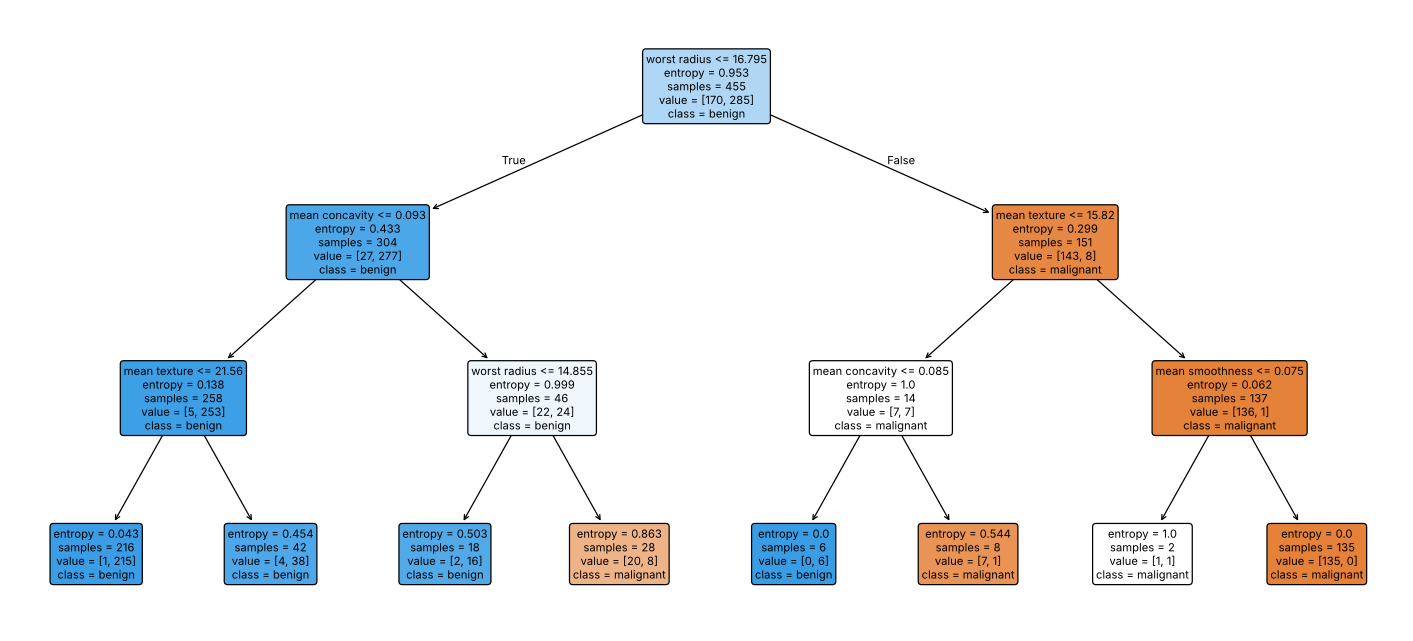

In [6]:
plt.figure(figsize=(20, 9))
plot_tree(tree, feature_names=X.columns, class_names=["malignant", "benign"], filled=True, rounded=True, fontsize=9)
plt.show()

In [7]:
def entropy(s):
    p = s.value_counts(normalize=True)
    return float(-(p * np.log2(p)).sum())

In [8]:
def gini(s):
    p = s.value_counts(normalize=True)
    return float(1 - (p ** 2).sum())

In [9]:
def best_cut(col):
    vals = np.sort(col.unique())
    best = (0, None)
    for t in (vals[:-1] + vals[1:]) / 2:
        left, right = y_train[col <= t], y_train[col > t]
        w = len(left) / len(y_train)
        gain = entropy(y_train) - (w * entropy(left) + (1 - w) * entropy(right))
        if gain > best[0]:
            best = (gain, t)
    return best

In [10]:
print("Parent entropy: %.4f, parent gini: %.4f" % (entropy(y_train), gini(y_train)))
table = pd.DataFrame([(c, *best_cut(X_train[c])[::-1]) for c in X.columns],
                     columns=["Feature", "Best threshold", "Information gain"])
table = table.sort_values("Information gain", ascending=False).reset_index(drop=True)
print(table.round(4))

Parent entropy: 0.9534, parent gini: 0.4681
           Feature  Best threshold  Information gain
0     worst radius         16.7950            0.5652
1   mean perimeter         98.8250            0.4780
2      mean radius         15.0450            0.4717
3   mean concavity          0.0933            0.4670
4  worst concavity          0.2080            0.3913
5     mean texture         18.6350            0.1613
6  mean smoothness          0.0895            0.1224
7    mean symmetry          0.1715            0.0869


In [11]:
root = X.columns[tree.tree_.feature[0]]
print("\nRoot chosen by sklearn:", root, "<=", round(tree.tree_.threshold[0], 3))
print("Root from manual calculation:", table.loc[0, "Feature"], "<=", round(table.loc[0, "Best threshold"], 3))


Root chosen by sklearn: worst radius <= 16.795
Root from manual calculation: worst radius <= 16.795


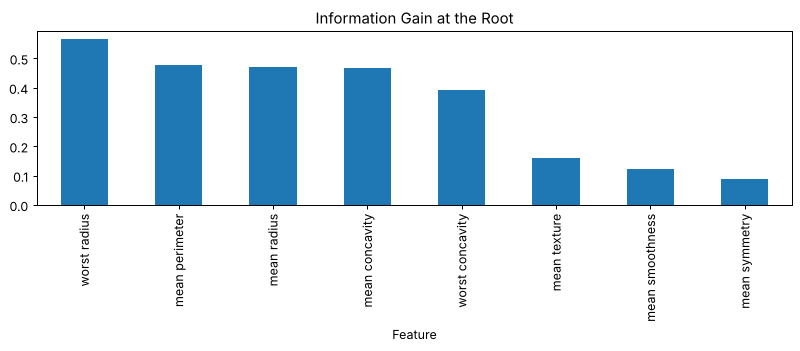

In [12]:
table.plot(x="Feature", y="Information gain", kind="bar", legend=False, figsize=(9, 4))
plt.title("Information Gain at the Root")
plt.tight_layout()
plt.show()

In [13]:
print("\nResult: %s is the root node because it has the highest information gain (%.4f);" % (table.loc[0, "Feature"], table.loc[0, "Information gain"]))
print("the depth-3 entropy tree reaches %.1f%% accuracy on the test set." % (accuracy_score(y_test, pred) * 100))


Result: worst radius is the root node because it has the highest information gain (0.5652);
the depth-3 entropy tree reaches 93.0% accuracy on the test set.
